In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("../data/final_mental_health_dataset.csv")

In [4]:
df.head()

,text,stress_level,emotion
0,Welcome to /r/depression's check-in post - a p...,High,Unknown
1,We understand that most people who reply immed...,High,Unknown
2,"I've always wanted to go back to school, the c...",High,Unknown
3,All I wan is to be loved. I just want someone...,High,Unknown
4,"I don’t even drive, didn’t finish my high scho...",High,Unknown


In [5]:
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-z\s]", "", text)
    tokens = text.split()
    tokens = [w for w in tokens if w not in stop_words]
    tokens = [lemmatizer.lemmatize(w) for w in tokens]
    return " ".join(tokens)

df["clean_text"] = df["text"].apply(clean_text)


In [6]:
from sklearn.model_selection import train_test_split

X = df["clean_text"]
y = df["stress_level"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=15000,
    ngram_range=(1,2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

lr_model.fit(X_train_tfidf, y_train)
lr_pred = lr_model.predict(X_test_tfidf)

print("Logistic Regression Results:\n")
print(classification_report(y_test, lr_pred))

Logistic Regression Results:

              precision    recall  f1-score   support

        High       0.73      0.75      0.74      1525
         Low       0.84      0.85      0.85      3339
      Medium       0.82      0.78      0.80      1436

    accuracy                           0.81      6300
   macro avg       0.80      0.79      0.79      6300
weighted avg       0.81      0.81      0.81      6300



In [9]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(class_weight="balanced")

svm_model.fit(X_train_tfidf, y_train)
svm_pred = svm_model.predict(X_test_tfidf)

print("SVM Results:\n")
print(classification_report(y_test, svm_pred))

SVM Results:

              precision    recall  f1-score   support

        High       0.73      0.71      0.72      1525
         Low       0.83      0.86      0.84      3339
      Medium       0.80      0.75      0.78      1436

    accuracy                           0.80      6300
   macro avg       0.79      0.77      0.78      6300
weighted avg       0.80      0.80      0.80      6300



In [10]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42
)

rf_model.fit(X_train_tfidf, y_train)
rf_pred = rf_model.predict(X_test_tfidf)

print("Random Forest Results:\n")
print(classification_report(y_test, rf_pred))


Random Forest Results:

              precision    recall  f1-score   support

        High       0.91      0.59      0.71      1525
         Low       0.77      0.97      0.86      3339
      Medium       0.92      0.71      0.80      1436

    accuracy                           0.82      6300
   macro avg       0.87      0.76      0.79      6300
weighted avg       0.84      0.82      0.81      6300



In [11]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc  = le.transform(y_test)

xgb_model = XGBClassifier(
    objective="multi:softprob",
    eval_metric="mlogloss",
    use_label_encoder=False
)

xgb_model.fit(X_train_tfidf, y_train_enc)
xgb_pred = xgb_model.predict(X_test_tfidf)

print("XGBoost Results:\n")
print(classification_report(y_test_enc, xgb_pred, target_names=le.classes_))

c:\Users\Lenovo\OneDrive\Documents\MindWatch-AI\.venv\Lib\site-packages\xgboost\training.py:199: UserWarning: [23:09:27] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Results:

              precision    recall  f1-score   support

        High       0.90      0.59      0.71      1525
         Low       0.77      0.96      0.85      3339
      Medium       0.91      0.69      0.78      1436

    accuracy                           0.81      6300
   macro avg       0.86      0.75      0.78      6300
weighted avg       0.83      0.81      0.80      6300



In [12]:
from sklearn.metrics import classification_report
import pandas as pd

def get_macro_f1(y_true, y_pred):
    report = classification_report(y_true, y_pred, output_dict=True)
    return report["macro avg"]["f1-score"]


In [13]:
results = []

# Logistic Regression
lr_f1 = get_macro_f1(y_test, lr_pred)
results.append(["Logistic Regression", lr_f1])

# SVM
svm_f1 = get_macro_f1(y_test, svm_pred)
results.append(["Linear SVM", svm_f1])

# Random Forest
rf_f1 = get_macro_f1(y_test, rf_pred)
results.append(["Random Forest", rf_f1])

# XGBoost
xgb_f1 = get_macro_f1(y_test_enc, xgb_pred)
results.append(["XGBoost", xgb_f1])


In [14]:
comparison_df = pd.DataFrame(
    results, columns=["Model", "Macro F1-Score"]
)

comparison_df.sort_values(by="Macro F1-Score", ascending=False)


,Model,Macro F1-Score
0,Logistic Regression,0.794843
2,Random Forest,0.791699
3,XGBoost,0.783501
1,Linear SVM,0.780218


In [15]:
import shap

explainer = shap.LinearExplainer(lr_model, X_train_tfidf)


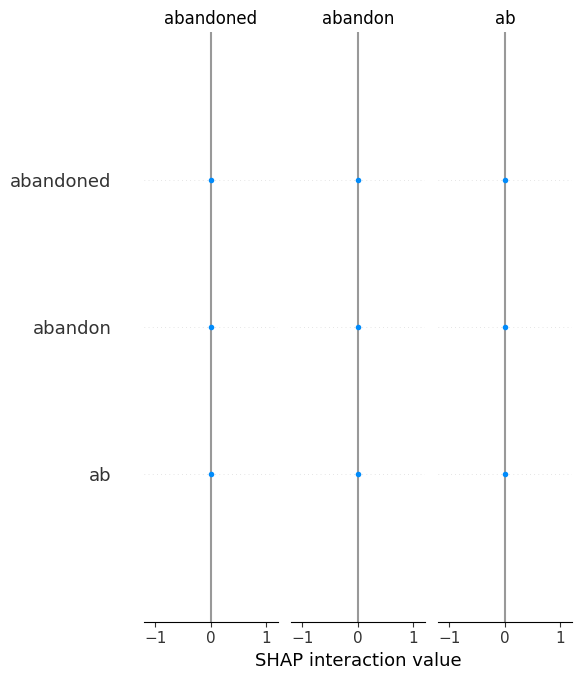

In [16]:
sample = X_test_tfidf[0]
shap_values = explainer.shap_values(sample)

shap.summary_plot(shap_values, feature_names=tfidf.get_feature_names_out())